# Supervised Learning — Logistic Regression

Baseline fraud classifier trained on the features built in `preprocessing.ipynb`.

Input: `data/processed/fraudTrain_features.csv`, `data/processed/fraudTest_features.csv`

This notebook covers:
1. Loading the processed data
2. Train / validation / test split (out-of-time)
3. Model pipeline (scaling + class-weighted logistic regression)
4. Validation: choosing regularisation `C` and the decision threshold
5. Final model on the test set
6. Coefficients and odds ratios
7. Results summary

**Metrics.** Fraud is ~0.5% of transactions, so accuracy is meaningless (predicting "never fraud" scores 99.5%). The main metric is **PR-AUC** (average precision), which focuses on how well the model ranks the rare fraud cases. ROC-AUC is reported for reference but looks optimistic on imbalanced data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
%matplotlib inline

DATA_DIR = Path("data/processed")

# Chart colours: blue/orange categorical, blue<->red diverging, muted greys for axes
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 1. Load data

In [2]:
train = pd.read_csv(DATA_DIR / "fraudTrain_features.csv")
test = pd.read_csv(DATA_DIR / "fraudTest_features.csv")

X_train_full = train.drop(columns=["is_fraud"]).astype("float32")
y_train_full = train["is_fraud"]
X_test = test.drop(columns=["is_fraud"]).astype("float32")
y_test = test["is_fraud"]

print("train:", X_train_full.shape, f"fraud rate {y_train_full.mean():.3%}")
print("test: ", X_test.shape, f"fraud rate {y_test.mean():.3%}")

train: (1296675, 83) fraud rate 0.579%
test:  (555719, 83) fraud rate 0.386%


## 2. Out-of-time validation split

The data is split three ways:

| Split | Rows | Period | Used for |
|---|---|---|---|
| **Train (fit)** | first 80% of `fraudTrain` | Jan 2019 – Mar 2020 | fitting model coefficients |
| **Validation** | last 20% of `fraudTrain` | Mar 2020 – Jun 2020 | choosing `C` and the decision threshold |
| **Test** | all of `fraudTest` | Jun 2020 – Dec 2020 | final evaluation, used once |

The training rows are in time order, so taking the last 20% as validation gives an **out-of-time** split, the same way the test set relates to the training set. A random split would let the model see transactions from the same days it is validated on, which overstates performance on future data.

In [3]:
cut = int(len(X_train_full) * 0.8)
X_tr, y_tr = X_train_full.iloc[:cut], y_train_full.iloc[:cut]
X_val, y_val = X_train_full.iloc[cut:], y_train_full.iloc[cut:]

pd.DataFrame({
    "rows": [len(X_tr), len(X_val), len(X_test)],
    "fraud": [y_tr.sum(), y_val.sum(), y_test.sum()],
    "fraud rate": [f"{y_tr.mean():.3%}", f"{y_val.mean():.3%}", f"{y_test.mean():.3%}"],
}, index=["train (fit)", "validation", "test"])

,rows,fraud,fraud rate
train (fit),1037340,5968,0.575%
validation,259335,1538,0.593%
test,555719,2145,0.386%


## 3. Model pipeline

- **Scaling.** Continuous features (amount, age, hour, …) are standardised so each coefficient means "change in log-odds per 1 standard deviation". The 0/1 columns (one-hot dummies and flags) are left as-is, so their coefficients mean "change in log-odds vs the baseline category". The scaler is fit on the training rows only, inside the pipeline.
- **`class_weight="balanced"`.** Each fraud case is weighted ~200× a legitimate one, so the model can't ignore the minority class. A side effect is that predicted probabilities are inflated (not calibrated), which is why the threshold is tuned in section 4 rather than left at 0.5.
- **Regularisation.** L2 penalty; its strength `C` (smaller = stronger) is chosen on the validation set in section 4.

In [4]:
binary_columns = [c for c in X_train_full.columns if X_train_full[c].isin([0, 1]).all()]
continuous_columns = [c for c in X_train_full.columns if c not in binary_columns]
print(f"{len(continuous_columns)} continuous (scaled):", continuous_columns)
print(f"{len(binary_columns)} binary (left as 0/1)")


def make_model(C=1.0):
    return Pipeline([
        ("scale", ColumnTransformer(
            [("continuous", StandardScaler(), continuous_columns)],
            remainder="passthrough",
            verbose_feature_names_out=False,
        )),
        ("logreg", LogisticRegression(C=C, class_weight="balanced", max_iter=2000)),
    ])

15 continuous (scaled): ['amt', 'city_pop', 'month', 'day_of_month', 'hour', 'day_of_week', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'age', 'log_amt', 'log_distance_km']
68 binary (left as 0/1)


## 4. Validation: choosing `C` and the threshold

### 4a. Regularisation strength

Each candidate `C` is fit on the train (fit) rows and scored on the validation rows by PR-AUC. The best `C` is kept.

In [5]:
results = []
models = {}
for C in [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0]:
    models[C] = make_model(C).fit(X_tr, y_tr)
    proba = models[C].predict_proba(X_val)[:, 1]
    results.append({
        "C": C,
        "val PR-AUC": average_precision_score(y_val, proba),
        "val ROC-AUC": roc_auc_score(y_val, proba),
    })

c_results = pd.DataFrame(results).set_index("C")
best_C = c_results["val PR-AUC"].idxmax()
print(f"Best C: {best_C}")
c_results.round(4)

Best C: 0.0001


,val PR-AUC,val ROC-AUC
C,,
0.00001,0.2439,0.9244
0.00010,0.2590,0.9511
0.00100,0.2490,0.9637
0.01000,0.2333,0.9663
0.10000,0.2287,0.9666
1.00000,0.2280,0.9666


In [6]:
model = models[best_C]
val_proba = model.predict_proba(X_val)[:, 1]

print(f"Validation PR-AUC:  {average_precision_score(y_val, val_proba):.4f}  (random = {y_val.mean():.4f})")
print(f"Validation ROC-AUC: {roc_auc_score(y_val, val_proba):.4f}")

Validation PR-AUC:  0.2590  (random = 0.0059)
Validation ROC-AUC: 0.9511


### 4b. Decision threshold

The default 0.5 threshold is poorly suited here: because of the class weighting it flags far too many legitimate transactions. The threshold that maximises **F1** (the balance of precision and recall) on the validation set is chosen instead. If the business cost of a missed fraud is much higher than a false alarm, a lower threshold (higher recall) could be picked from the same curve.

Best-F1 threshold: 0.8775

Validation report at the chosen threshold:
              precision    recall  f1-score   support

  legitimate      0.998     0.993     0.995    257797
       fraud      0.347     0.644     0.451      1538

    accuracy                          0.991    259335
   macro avg      0.673     0.818     0.723    259335
weighted avg      0.994     0.991     0.992    259335



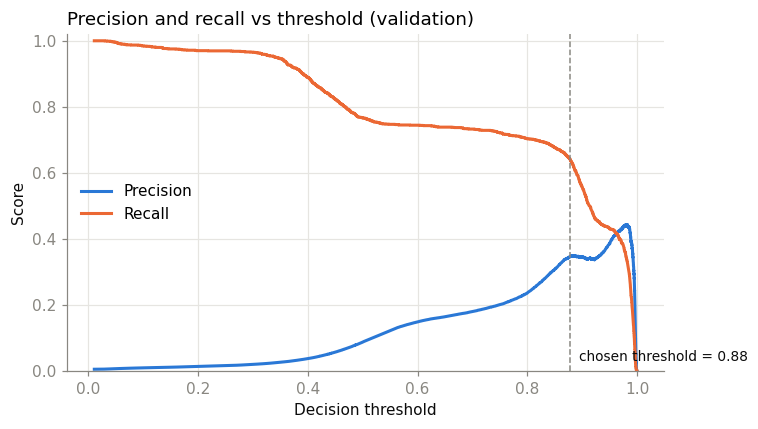

In [7]:
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
best = np.argmax(f1)
threshold = thresholds[best]

print(f"Best-F1 threshold: {threshold:.4f}\n")
print("Validation report at the chosen threshold:")
print(classification_report(y_val, (val_proba >= threshold).astype(int),
                            target_names=["legitimate", "fraud"], digits=3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], color=BLUE, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, label="Recall")
ax.axvline(threshold, color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"chosen threshold = {threshold:.2f}", (threshold, 0.03),
            xytext=(6, 0), textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.set_title("Precision and recall vs threshold (validation)", loc="left")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()
plt.show()

## 5. Final model on the test set

With `C` and the threshold fixed from validation, the model is refit on the **full** training set (fit + validation rows, so the most recent months are included) and evaluated once on the test set, at both the default 0.5 threshold and the tuned threshold.

In [8]:
final_model = make_model(best_C).fit(X_train_full, y_train_full)
test_proba = final_model.predict_proba(X_test)[:, 1]

print(f"Test PR-AUC:  {average_precision_score(y_test, test_proba):.4f}  (random = {y_test.mean():.4f})")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")

for name, t in [("default 0.5", 0.5), (f"tuned {threshold:.2f}", threshold)]:
    print(f"\n=== Threshold: {name} ===")
    print(classification_report(y_test, (test_proba >= t).astype(int),
                                target_names=["legitimate", "fraud"], digits=3))

Test PR-AUC:  0.1940  (random = 0.0039)
Test ROC-AUC: 0.9513

=== Threshold: default 0.5 ===
              precision    recall  f1-score   support

  legitimate      0.999     0.965     0.982    553574
       fraud      0.076     0.738     0.137      2145

    accuracy                          0.964    555719
   macro avg      0.537     0.852     0.559    555719
weighted avg      0.995     0.964     0.978    555719


=== Threshold: tuned 0.88 ===
              precision    recall  f1-score   support

  legitimate      0.999     0.993     0.996    553574
       fraud      0.264     0.624     0.371      2145

    accuracy                          0.992    555719
   macro avg      0.631     0.809     0.684    555719
weighted avg      0.996     0.992     0.993    555719



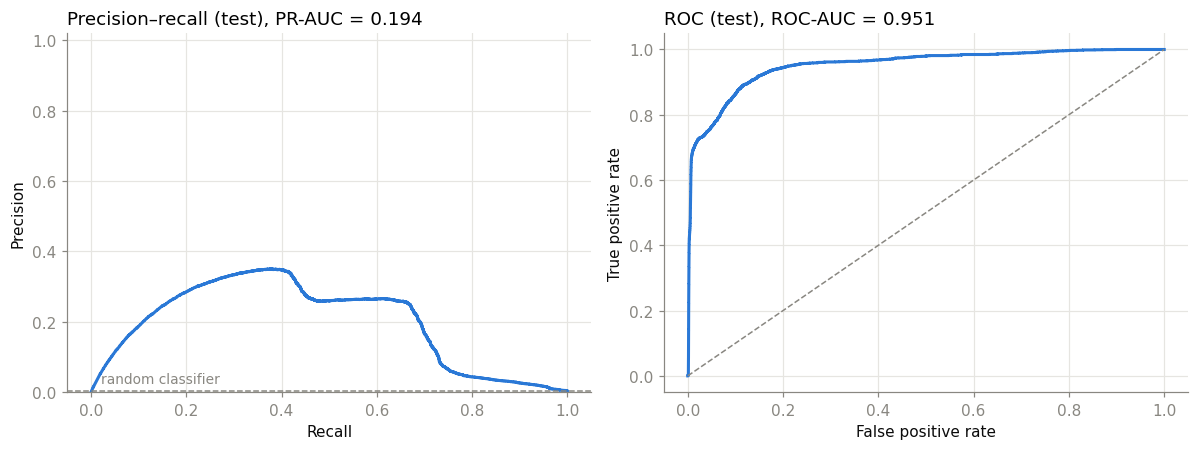

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[0].plot(r[:-1], p[:-1], color=BLUE)  # drop sklearn's artificial (recall=0, precision=1) end point
axes[0].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
axes[0].annotate("random classifier", (0.02, y_test.mean()), xytext=(0, 5),
                 textcoords="offset points", color=MUTED, fontsize=9)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_ylim(0, 1.02)
axes[0].set_title(f"Precision–recall (test), PR-AUC = {average_precision_score(y_test, test_proba):.3f}", loc="left")

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title(f"ROC (test), ROC-AUC = {roc_auc_score(y_test, test_proba):.3f}", loc="left")

plt.tight_layout()
plt.show()

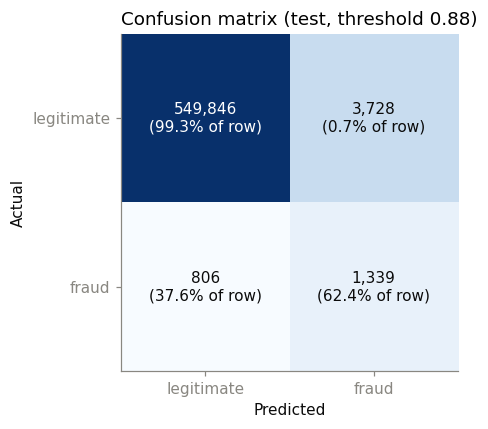

,predicted legitimate,predicted fraud
actual legitimate,549846,3728
actual fraud,806,1339


In [10]:
cm = confusion_matrix(y_test, (test_proba >= threshold).astype(int))
labels = ["legitimate", "fraud"]

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(np.log10(cm + 1), cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n({share:.1%} of row)", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 10 else INK)
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix (test, threshold {threshold:.2f})", loc="left")
plt.tight_layout()
plt.show()

pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"predicted {l}" for l in labels])

## 6. Coefficients and odds ratios

Because multicollinearity was removed in preprocessing (all VIFs < 10), the coefficients can be read individually:

- **Continuous features:** odds ratio = multiplicative change in the odds of fraud for a **1 standard deviation** increase.
- **Dummies:** odds ratio vs the **baseline category** (`gas_transport` for category, `F` for gender, `TX` for state).

Odds ratio > 1 means higher fraud risk, < 1 lower. Note that these are associations within this simulated dataset, not causal effects.

In [11]:
feature_names = final_model.named_steps["scale"].get_feature_names_out()
coefs = pd.DataFrame({
    "feature": feature_names,
    "coef": final_model.named_steps["logreg"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs["scaled"] = coefs["feature"].isin(continuous_columns)
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.head(20).round(3)

,feature,coef,odds_ratio,scaled
0,amt_is_large,1.527,4.604,False
1,hour_cos,1.069,2.913,True
2,amt,1.024,2.785,True
3,category_shopping_pos,-0.746,0.474,False
4,category_shopping_net,-0.662,0.516,False
5,log_amt,-0.472,0.624,True
6,category_misc_net,-0.467,0.627,False
7,category_entertainment,-0.427,0.653,False
8,category_home,-0.341,0.711,False
9,hour_sin,0.263,1.301,True


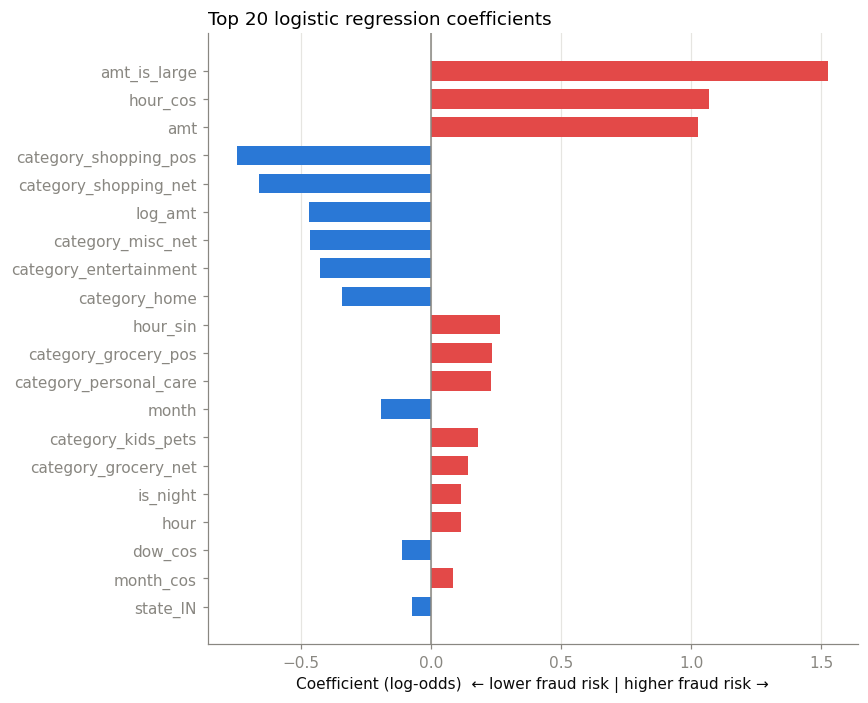

In [12]:
top = coefs.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, RED, BLUE), height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coefficient (log-odds)  ← lower fraud risk | higher fraud risk →")
ax.set_title("Top 20 logistic regression coefficients", loc="left")
plt.tight_layout()
plt.show()

## 7. Results summary

| | Validation (Mar–Jun 2020) | Test (Jun–Dec 2020) |
|---|---|---|
| PR-AUC (random ≈ 0.004–0.006) | 0.259 | 0.194 |
| ROC-AUC | 0.951 | 0.951 |
| Fraud precision @ threshold 0.88 | 0.347 | 0.264 |
| Fraud recall @ threshold 0.88 | 0.644 | 0.624 |
| Fraud F1 @ threshold 0.88 | 0.451 | 0.371 |

- **Chosen settings (from validation only):** `C = 0.0001` (strong regularisation; the best PR-AUC sat inside the tested range) and threshold `0.88`.
- **On the test set** the model catches **62% of fraud** (1,339 of 2,145) while flagging 0.7% of legitimate transactions (3,728 false alarms), so roughly **1 in 4 alerts is real fraud**.
- **The threshold matters.** At the default 0.5, recall is higher (74%) but precision collapses to 7.6% (about 13 false alarms per fraud caught), because `class_weight="balanced"` inflates the predicted probabilities.
- **Validation → test drop** (PR-AUC 0.26 → 0.19) is expected: the test period is later and has a lower fraud rate (0.39% vs 0.59%).

**Reading the coefficients**
- The strongest signals are **large amounts** (`amt_is_large`, `amt`) and **time of day**: `hour_cos` is positive, and `hour_cos` is highest around midnight, so late-night transactions are riskier.
- `amt` (+) and `log_amt` (−) should be read **together**: they jointly bend the amount effect into a curve rather than a straight line.
- Category coefficients are **conditional on amount and time**. For example, `shopping_net` has one of the highest raw fraud rates in the EDA, but a negative coefficient here: once the (large) transaction amount is accounted for, the category itself adds less risk than the `gas_transport` baseline.

**Limitations / next steps.** Logistic regression can only add up effects; fraud here clearly depends on *combinations* (amount × category × hour). Tree-based models (random forest, XGBoost), which learn such interactions automatically, are the natural next comparison using the same train / validation / test split.